# Cooperative Name Search & Duplicate Detection
**AI-assisted member/cooperative name search: from loading the data to comparing models on many metrics**

Pipeline (CRISP-DM, per the capstone deck): Query → Normalize → Retrieve (TF-IDF) → Classify (match probability) → Human review.

**Important data note:** the Ushirika CSVs hold *aggregate statistics only* (no cooperative names). We use them to shape a **synthetic register** (size per region, SACCOS share, crop vocabulary). Duplicate labels are simulated with realistic noise, so scores show the pipeline works, **not** real-world accuracy. Swap in the approved extract in Step 6 when available.

Similarity is evidence, not proof of identity. Nothing here merges, deletes or approves records.

## 1. Imports and configuration

In [1]:
import glob, random, re, unicodedata, warnings
from pathlib import Path
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             log_loss, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 80)

SEED = 42
OUT = Path("coop_search_outputs"); OUT.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
rng = random.Random(SEED)

BAND_LIKELY, BAND_REVIEW = 0.90, 0.50

GENERIC = {"ltd", "limited", "cooperative", "society", "saccos", "amcos", "union", "co", "operative"}

WORDS = """umoja amani upendo tumaini baraka neema ushindi maendeleo jitegemee mshikamano
uhuru mwangaza imani furaha heshima subira nguvu kilimo mavuno tafara bidii juhudi
mapinduzi kazi tegemeo faraja ujamaa harambee mwanga pamoja chemchem msingi nuru
wakulima wafugaji wavuvi wanawake vijana mkombozi kilele mlima bonde ziwa mto jua
kijiji kijani zawadi hazina tunu azimio sifa ridhaa shukrani amka songa mbele""".split()

OTHER_KINDS = ["Dairy", "Fishing", "Women", "Youth", "Livestock", "Housing", "Transport",
               "Irrigation", "Mining", "Consumer"]

DEFAULT_CROPS = ["Coffee", "Cotton", "Cashew", "Tea", "Tobacco", "Sisal", "Maize", "Sesame"]

## 2. Load the datasets
Finds the two Ushirika CSVs wherever they are (current folder or the uploads folder).

In [2]:
def find(suffix):
    hits = glob.glob(f"**/*{suffix}", recursive=True) + glob.glob(f"/mnt/user-data/attachments/**/*{suffix}", recursive=True)
    if not hits: raise FileNotFoundError(f"Put *{suffix} next to this notebook")
    return hits[0]

MASTER   = find("tanzania_ushirika_master.csv")
REGIONAL = find("tanzania_ushirika_regional_analysis.csv")
master   = pd.read_csv(MASTER)
regional = pd.read_csv(REGIONAL)
print("master:", master.shape, "| regional:", regional.shape)
display(master.head())

master: (1905, 8) | regional: (31, 30)


,category,entity_type,entity,indicator,period,value,note,source
0,agriculture_trade,national,Tanzania,Cashew_Production_Tonnes,2019,225053,NaN,TCDC/Ushirika statistics (ushirika.go.tz) | NBS Statistical Abstract 2024 / ...
1,agriculture_trade,national,Tanzania,Coffee_Production_Tonnes,2019,68147,NaN,TCDC/Ushirika statistics (ushirika.go.tz) | NBS Statistical Abstract 2024 / ...
2,agriculture_trade,national,Tanzania,Cotton_Production_Tonnes,2019,348910,NaN,TCDC/Ushirika statistics (ushirika.go.tz) | NBS Statistical Abstract 2024 / ...
3,agriculture_trade,national,Tanzania,Tea_Production_Tonnes,2019,37193,NaN,TCDC/Ushirika statistics (ushirika.go.tz) | NBS Statistical Abstract 2024 / ...
4,agriculture_trade,national,Tanzania,Tobacco_Production_Tonnes,2019,70824,NaN,TCDC/Ushirika statistics (ushirika.go.tz) | NBS Statistical Abstract 2024 / ...


In [3]:
display(master.category.value_counts().to_frame("rows"))
display(master.entity_type.value_counts().to_frame("rows"))
print("Crops in master:", sorted(master.loc[master.entity_type == "crop", "entity"].dropna().unique()))

,rows
category,
finance_access,792
agriculture_trade,298
cooperatives,278
impact_employment,199
impact_poverty,162
demography,155
risk,17
impact_inclusion,4


,rows
entity_type,
region,1429
national,302
crop,92
asset_type,27
cooperative,24
agro_input,20
coop_type,7
category,4


Crops in master: ['Cashew Nuts', 'Chick Peas', 'Cocoa', 'Coffee', 'Cotton', 'Green Gram', 'Maize', 'Pigeon Peas', 'Pyrethrum', 'Sesame', 'Sisal', 'Soya Beans', 'Soybeans', 'Sugar Cane', 'Sugarcane', 'TOTAL', 'Tea', 'Tobacco']


In [4]:
cols = ["region", "zone", "population_2022", "cooperatives_total_jun2025", "saccos_registered_dec2023", "saccos_licensed_jun2025"]
display(regional[cols].head(10))
print("Missing values per column (Zanzibar rows have no cooperative data):")
display(regional[cols].isna().sum().to_frame("missing"))

,region,zone,population_2022,cooperatives_total_jun2025,saccos_registered_dec2023,saccos_licensed_jun2025
0,Arusha,Mainland,2356255,234.0,133.0,106.0
1,Dar es Salaam,Mainland,5383728,675.0,293.0,271.0
2,Dodoma,Mainland,3085625,158.0,55.0,51.0
3,Geita,Mainland,2977608,583.0,26.0,13.0
4,Iringa,Mainland,1192728,191.0,49.0,37.0
5,Kagera,Mainland,2989299,362.0,46.0,37.0
6,Katavi,Mainland,1152958,56.0,5.0,3.0
7,Kigoma,Mainland,2470967,224.0,23.0,7.0
8,Kilimanjaro,Mainland,1861934,300.0,83.0,82.0
9,Lindi,Mainland,1194028,200.0,11.0,3.0


Missing values per column (Zanzibar rows have no cooperative data):


,missing
region,0
zone,0
population_2022,0
cooperatives_total_jun2025,5
saccos_registered_dec2023,5
saccos_licensed_jun2025,5


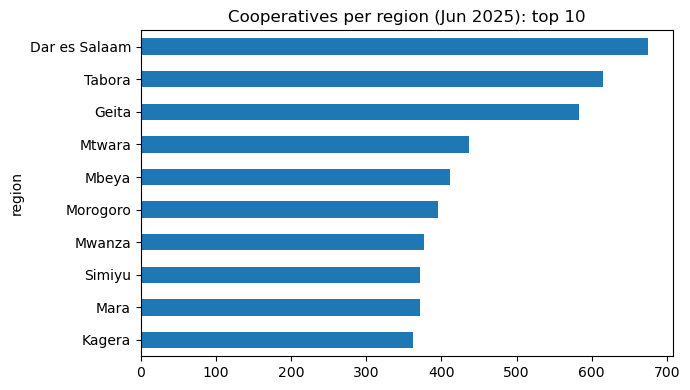

In [5]:
top = regional.dropna(subset=["cooperatives_total_jun2025"]).nlargest(10, "cooperatives_total_jun2025")
top.plot.barh(x="region", y="cooperatives_total_jun2025", legend=False, figsize=(7, 4), title="Cooperatives per region (Jun 2025): top 10")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 3. Text normalisation
Lower-case, strip accents/punctuation, standardise abbreviations (Ltd/Limited, Sacco/Saccos...). A crude **phonetic key** merges sounds often confused in local spellings (l/r, b/v, c/k, e/i, o/u), e.g. *Tafara* vs *Tafala*.

In [6]:
def normalize(s: str) -> str:
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    s = s.replace("&", " and ")
    s = re.sub(r"(?<=\b[a-z])\.(?=[a-z]\b)", "", s)          # s.a.c.c.o.s -> saccos
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    toks = []
    for t in s.split():
        t = {"limited": "ltd", "sacco": "saccos", "coop": "cooperative", "co": "cooperative",
             "soc": "society", "operative": "cooperative"}.get(t, t)
        toks.append(t)
    return " ".join(toks)

def core_tokens(norm: str):
    return [t for t in norm.split() if t not in GENERIC]

def coop_type(norm: str) -> str:
    return "amcos" if "amcos" in norm.split() else "saccos" if "saccos" in norm.split() else "other"

def phon_token(t: str) -> str:
    """Crude phonetic key for East/Southern African naming: l/r, b/v, c/k, ph/f, e/i, o/u merge."""
    for a, b in [("ph", "f"), ("sh", "s"), ("ch", "c"), ("ck", "k"), ("th", "t"), ("ee", "i"), ("oo", "u")]:
        t = t.replace(a, b)
    t = t.translate(str.maketrans({"c": "k", "v": "b", "l": "r", "y": "i", "w": "u", "z": "s",
                                   "q": "k", "e": "i", "o": "u"}))
    return re.sub(r"(.)\1+", r"\1", t)

def phon_key(norm: str) -> str:
    return " ".join(phon_token(t) for t in norm.split())

for s in ["Umoja Kahawa A.M.C.O.S Limited", "TAFARA  Women Co-operative Soc.", "Tafala Women Cooperative Society"]:
    print(f"{s!r:45} -> {normalize(s)!r:40} phon={phon_key(normalize(s))!r}  type={coop_type(normalize(s))}")

'Umoja Kahawa A.M.C.O.S Limited'              -> 'umoja kahawa amcos ltd'                 phon='umuja kahaua amkus rtd'  type=amcos
'TAFARA  Women Co-operative Soc.'             -> 'tafara women cooperative cooperative society' phon='tafara umin kupiratibi kupiratibi sukiti'  type=other
'Tafala Women Cooperative Society'            -> 'tafala women cooperative society'       phon='tafara umin kupiratibi sukiti'  type=other


## 4. String-similarity metrics (written from scratch)
Levenshtein ratio, Jaro-Winkler, n-gram Jaccard/Dice and a soft token match on the *distinctive* words.

In [7]:
def lev(a: str, b: str) -> int:
    if a == b:
        return 0
    if not a or not b:
        return max(len(a), len(b))
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def lev_ratio(a, b):
    m = max(len(a), len(b))
    return 1.0 if m == 0 else 1 - lev(a, b) / m

def jaro_winkler(s, t, p=0.1):
    if s == t:
        return 1.0
    ls, lt = len(s), len(t)
    if not ls or not lt:
        return 0.0
    md = max(max(ls, lt) // 2 - 1, 0)
    sm, tm, m = [False] * ls, [False] * lt, 0
    for i, c in enumerate(s):
        for j in range(max(0, i - md), min(i + md + 1, lt)):
            if not tm[j] and t[j] == c:
                sm[i] = tm[j] = True
                m += 1
                break
    if m == 0:
        return 0.0
    k = tr = 0
    for i in range(ls):
        if sm[i]:
            while not tm[k]:
                k += 1
            tr += s[i] != t[k]
            k += 1
    j = (m / ls + m / lt + (m - tr // 2) / m) / 3
    pre = 0
    for a, b in zip(s[:4], t[:4]):
        if a != b:
            break
        pre += 1
    return j + pre * p * (1 - j)

def ngrams(s, n):
    s = f" {s} "
    return {s[i:i + n] for i in range(max(len(s) - n + 1, 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 1.0

def dice(a, b):
    return 2 * len(a & b) / (len(a) + len(b)) if (a or b) else 1.0

def soft_core_match(ca, cb):
    """Mean best Jaro-Winkler match of each core token to the other side (symmetric)."""
    if not ca or not cb:
        return 0.0
    f = lambda x, y: np.mean([max(jaro_winkler(t, u) for u in y) for t in x])
    return (f(ca, cb) + f(cb, ca)) / 2

a, b = normalize("Mlima Zawadi SACCOS Ltd"), normalize("Mrima Zawadi Saccos Limited")
print("levenshtein distance :", lev(a, b))
print("levenshtein ratio    :", round(lev_ratio(a, b), 3))
print("jaro-winkler         :", round(jaro_winkler(a, b), 3))
print("char 3-gram jaccard  :", round(jaccard(ngrams(a, 3), ngrams(b, 3)), 3))
print("char 2-gram dice     :", round(dice(ngrams(a, 2), ngrams(b, 2)), 3))
print("soft core match      :", round(soft_core_match(core_tokens(a), core_tokens(b)), 3))

levenshtein distance : 1
levenshtein ratio    : 0.957
jaro-winkler         : 0.974
char 3-gram jaccard  : 0.769
char 2-gram dice     : 0.917
soft core match      : 0.94


## 5. Pair-feature engineering
Each (query, candidate) pair becomes 18 numeric features. These are what the classifiers learn from.

In [8]:
FEATURES = ["lev_ratio", "jaro_winkler", "token_jaccard", "token_sort_ratio", "overlap_coef",
            "core_jaccard", "core_soft_match", "char3_jaccard", "char2_dice", "tfidf_cosine",
            "phonetic_equal", "phonetic_lev", "len_diff", "first_token_match", "initials_match",
            "region_agree", "type_agree", "exact_norm"]

def pair_features(a_raw, b_raw, ra, rb, vec) -> pd.DataFrame:
    na, nb = [normalize(x) for x in a_raw], [normalize(x) for x in b_raw]
    va, vb = vec.transform(na), vec.transform(nb)
    cos = np.asarray(va.multiply(vb).sum(axis=1)).ravel()
    rows = []
    for i, (x, y) in enumerate(zip(na, nb)):
        tx, ty = x.split(), y.split()
        sx, sy = set(tx), set(ty)
        cx, cy = core_tokens(x), core_tokens(y)
        px, py = phon_key(x), phon_key(y)
        r1, r2 = normalize(ra[i]), normalize(rb[i])
        rows.append([
            lev_ratio(x, y), jaro_winkler(x, y), jaccard(sx, sy),
            lev_ratio(" ".join(sorted(tx)), " ".join(sorted(ty))),
            len(sx & sy) / max(min(len(sx), len(sy)), 1),
            jaccard(set(cx), set(cy)), soft_core_match(cx, cy),
            jaccard(ngrams(x, 3), ngrams(y, 3)), dice(ngrams(x, 2), ngrams(y, 2)), cos[i],
            float(px == py), lev_ratio(px, py), abs(len(x) - len(y)) / max(len(x), len(y), 1),
            float(bool(tx and ty and tx[0] == ty[0])),
            float("".join(t[0] for t in tx) == "".join(t[0] for t in ty)),
            -1.0 if not r1 or not r2 else float(r1 == r2),
            float(coop_type(x) == coop_type(y)), float(x == y)])
    return pd.DataFrame(rows, columns=FEATURES)

def evidence(row: pd.Series) -> str:
    ev = []
    if row.exact_norm: ev.append("identical after normalisation")
    if row.phonetic_equal and not row.exact_norm: ev.append("phonetically identical")
    if row.core_soft_match >= 0.92: ev.append(f"distinctive words agree ({row.core_soft_match:.0%})")
    elif row.core_soft_match < 0.75: ev.append("distinctive words differ")
    if row.char3_jaccard >= 0.7: ev.append(f"character n-grams overlap ({row.char3_jaccard:.0%})")
    if row.token_sort_ratio > row.lev_ratio + 0.15: ev.append("same words, different order")
    if row.region_agree == 1: ev.append("same region")
    elif row.region_agree == 0: ev.append("different region")
    if not row.type_agree: ev.append("different society type")
    return "; ".join(ev) or "weak similarity only"

## 6. Build the register
Uses the CSVs: cooperatives per region (scaled), SACCOS share, crop list. **To use real data later:** replace `register` with `pd.read_csv('approved_extract.csv')` having columns `name`, `region`, then add `ctype` and `coop_id` as below.

In [9]:
def load_inputs(master, regional):
    reg = pd.read_csv(regional)
    reg = reg.dropna(subset=["cooperatives_total_jun2025"]).copy()
    reg["sacco_share"] = (reg["saccos_registered_dec2023"] / reg["cooperatives_total_jun2025"]).clip(0.03, 0.6)
    crops = DEFAULT_CROPS
    try:
        m = pd.read_csv(master)
        found = m.loc[m.entity_type == "crop", "entity"].dropna().astype(str)
        found = [c for c in found.unique() if c.lower() not in {"soya beans", "sugar cane", "cotton sulphur", "total", "others"}]
        crops = [c.replace(" Nuts", "") for c in found] or DEFAULT_CROPS
    except Exception as e:  # master is optional
        print(f"[warn] master file not used ({e}); default crops")
    return reg, sorted(set(crops))

def make_register(reg, crops, scale, rng):
    names, rows = set(), []
    for _, r in reg.iterrows():
        n = max(int(round(r.cooperatives_total_jun2025 * scale)), 3)
        for _ in range(n):
            for _try in range(50):
                w = rng.choice(WORDS).capitalize()
                if rng.random() < 0.35:
                    w += " " + rng.choice(WORDS).capitalize()
                u = rng.random()
                if u < r.sacco_share:
                    ctype, nm = "saccos", f"{w} SACCOS Ltd"
                elif u < r.sacco_share + (1 - r.sacco_share) * 0.6:
                    ctype, nm = "amcos", f"{w} {rng.choice(crops)} AMCOS Ltd"
                else:
                    ctype, nm = "other", f"{w} {rng.choice(OTHER_KINDS)} Cooperative Society Ltd"
                if normalize(nm) not in names:
                    names.add(normalize(nm))
                    rows.append((nm, r.region, ctype))
                    break
    df = pd.DataFrame(rows, columns=["name", "region", "ctype"])
    df.insert(0, "coop_id", [f"C{i:05d}" for i in range(len(df))])
    return df

SCALE = 0.25                       # fraction of real cooperative counts to simulate
reg_stats, crops = load_inputs(MASTER, REGIONAL)
register = make_register(reg_stats, crops, SCALE, rng)
register.to_csv(OUT / "register_synthetic.csv", index=False)
print(len(register), "cooperatives |", register.region.nunique(), "regions | crops:", crops)
display(register.sample(8, random_state=1))
display(register.ctype.value_counts().to_frame("count"))

1996 cooperatives | 26 regions | crops: ['Cashew', 'Chick Peas', 'Cocoa', 'Coffee', 'Cotton', 'Green Gram', 'Maize', 'Pigeon Peas', 'Pyrethrum', 'Sesame', 'Sisal', 'Soybeans', 'Sugarcane', 'Tea', 'Tobacco']


,coop_id,name,region,ctype
608,C00608,Jitegemee Mkombozi Youth Cooperative Society Ltd,Kigoma,other
1695,C01695,Tegemeo Ushindi Pigeon Peas AMCOS Ltd,Singida,amcos
790,C00790,Neema Transport Cooperative Society Ltd,Mara,other
650,C00650,Wanawake Hazina SACCOS Ltd,Kilimanjaro,saccos
1634,C01634,Tumaini Ujamaa Green Gram AMCOS Ltd,Simiyu,amcos
625,C00625,Maendeleo Housing Cooperative Society Ltd,Kilimanjaro,other
763,C00763,Uhuru Sisal AMCOS Ltd,Manyara,amcos
447,C00447,Jua Mwanga Pigeon Peas AMCOS Ltd,Iringa,amcos


,count
ctype,
amcos,1064
other,729
saccos,203


## 7. Noise model: simulating how people mis-type names
Typos, phonetic swaps, abbreviation changes, merged/dropped words, reordering and case. Used to create duplicate (positive) queries.

In [10]:
SUBS = [("l", "r"), ("r", "l"), ("b", "v"), ("v", "b"), ("c", "k"), ("k", "c"), ("ph", "f"),
        ("f", "ph"), ("s", "z"), ("i", "e"), ("e", "i"), ("o", "u"), ("u", "o"), ("w", "u")]
ABBR = {"ltd": ["Limited", "Ltd.", "LTD"], "saccos": ["Sacco", "S.A.C.C.O.S", "Saccos"],
        "amcos": ["A.M.C.O.S", "Amcos", "AMCOS."], "cooperative": ["Coop", "Co-operative"],
        "society": ["Soc."]}

def add_noise(name, rng, force=False):
    toks = name.split()
    ops = rng.sample(["typo", "phon", "abbr", "space", "drop", "order", "case"], k=rng.choice([1, 1, 2, 3]))
    if not force and rng.random() < 0.08:
        return name                                   # unchanged repeat submission
    for op in ops:
        idx = [i for i, t in enumerate(toks) if t.lower() not in GENERIC and len(t) >= 3] or list(range(len(toks)))
        i = rng.choice(idx)
        t = toks[i]
        if op == "typo" and len(t) >= 3:
            p, k = rng.randrange(len(t)), rng.choice(["sub", "del", "ins", "swap"])
            ch = rng.choice("abcdefghijklmnopqrstuvwxyz")
            t = {"sub": t[:p] + ch + t[p + 1:], "del": t[:p] + t[p + 1:], "ins": t[:p] + ch + t[p:],
                 "swap": t[:p] + t[p + 1:p + 2] + t[p:p + 1] + t[p + 2:]}[k]
            toks[i] = t
        elif op == "phon":
            cand = [(a, b) for a, b in SUBS if a in t.lower()]
            if cand:
                a, b = rng.choice(cand)
                toks[i] = re.sub(a, b, t, count=1, flags=re.I)
        elif op == "abbr":
            j = [k for k, x in enumerate(toks) if normalize(x) in ABBR or x.lower().strip(".") in ABBR]
            if j:
                k = rng.choice(j)
                key = normalize(toks[k]) if normalize(toks[k]) in ABBR else toks[k].lower().strip(".")
                toks[k] = rng.choice(ABBR[key])
        elif op == "space" and len(toks) > 1:
            k = rng.randrange(len(toks) - 1)
            toks[k:k + 2] = [toks[k] + toks[k + 1]]
        elif op == "drop" and len(toks) > 2:
            gen = [k for k, x in enumerate(toks) if normalize(x) in GENERIC]
            toks.pop(rng.choice(gen) if gen and rng.random() < 0.7 else rng.randrange(len(toks)))
        elif op == "order" and len(toks) > 2:
            k = rng.randrange(len(toks) - 1)
            toks[k], toks[k + 1] = toks[k + 1], toks[k]
        elif op == "case":
            toks = [x.upper() if rng.random() < .5 else x.lower() for x in toks]
    return " ".join(toks)

demo = register.name[0]
print("original:", demo)
for _ in range(6): print("  variant:", add_noise(demo, rng, force=True))

original: Mlima Zawadi SACCOS Ltd
  variant: Mlima Zawadi SACCOS Limited
  variant: Mlima Zawadi SACCOS LTD
  variant: MLIMA zawadisaccos
  variant: MLIMA zauadi saccos ltd
  variant: Mlema ZawadiSACCOS
  variant: MlimaZawadi SACCOS


## 8. Retrieval vectoriser and train/test split
TF-IDF over character 2–4-grams finds candidate names. The split is **by cooperative** (not by pair), so no name appears in both train and test.

In [11]:
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True)
vec.fit([normalize(x) for x in register.name])

tr_i, te_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(register, groups=register.coop_id))
tr_e, te_e = register.iloc[tr_i], register.iloc[te_i]
print("train cooperatives:", len(tr_e), "| test cooperatives:", len(te_e))

train cooperatives: 1596 | test cooperatives: 400


## 9. Build labelled pairs and compute features
Per cooperative: 2 noisy duplicates (label 1); **hard negatives** that look similar (nearest TF-IDF neighbours, including same-region ones so region alone can't give the answer); plus 1 random negative (label 0).

In [12]:
def build_pairs(ents, vec, rng, n_pos=2, n_hard=3, n_same=3, n_rand=1, p_region=0.85):
    ents = ents.reset_index(drop=True)
    norm = [normalize(x) for x in ents.name]
    sim = (vec.transform(norm) @ vec.transform(norm).T).toarray()
    np.fill_diagonal(sim, -1)
    A, B, RA, RB, Y, G = [], [], [], [], [], []

    def add(q, i, j, y):
        A.append(q); B.append(ents.name[j]); Y.append(y); G.append(ents.coop_id[i])
        RA.append(ents.region[i] if rng.random() < p_region else ""); RB.append(ents.region[j])

    for i in range(len(ents)):
        for _ in range(n_pos):
            add(add_noise(ents.name[i], rng), i, i, 1)
        for j in np.argsort(-sim[i])[:n_hard + 2][:n_hard]:       # hard negatives: look-alikes
            add(add_noise(ents.name[i], rng), i, int(j), 0)
        # same-region look-alikes, so region agreement alone cannot separate the classes
        same = [int(j) for j in np.argsort(-sim[i]) if ents.region[j] == ents.region[i]][:n_hard + 2]
        for j in rng.sample(same, min(n_same, len(same))):
            add(add_noise(ents.name[i], rng), i, j, 0)
        for _ in range(n_rand):
            j = rng.randrange(len(ents))
            if j != i:
                add(add_noise(ents.name[i], rng), i, j, 0)
    return A, B, RA, RB, np.array(Y), np.array(G)

Xtr_raw = build_pairs(tr_e, vec, rng)
Xte_raw = build_pairs(te_e, vec, rng)
Xtr = pair_features(*Xtr_raw[:4], vec)[FEATURES]; ytr, gtr = Xtr_raw[4], Xtr_raw[5]
Xte = pair_features(*Xte_raw[:4], vec)[FEATURES]; yte    = Xte_raw[4]
print(f"train pairs {len(ytr)} ({ytr.mean():.0%} duplicates) | test pairs {len(yte)} ({yte.mean():.0%} duplicates)")
display(Xtr.assign(label=ytr).head())

train pairs 14363 (22% duplicates) | test pairs 3600 (22% duplicates)


,lev_ratio,jaro_winkler,token_jaccard,token_sort_ratio,overlap_coef,core_jaccard,core_soft_match,char3_jaccard,char2_dice,tfidf_cosine,phonetic_equal,phonetic_lev,len_diff,first_token_match,initials_match,region_agree,type_agree,exact_norm,label
0,0.956522,0.982609,0.60,0.956522,0.750000,0.333333,0.966667,0.769231,0.916667,0.894974,1.0,1.000000,0.000000,1.0,1.0,1.0,1.0,0.0,1
1,0.956522,0.982609,0.60,0.956522,0.750000,0.333333,0.966667,0.769231,0.916667,0.894974,1.0,1.000000,0.000000,1.0,1.0,1.0,1.0,0.0,1
2,0.636364,0.810606,0.40,0.636364,0.666667,0.000000,0.823889,0.461538,0.750000,0.469126,0.0,0.619048,0.272727,0.0,0.0,1.0,1.0,0.0,0
3,0.521739,0.826219,0.60,0.521739,0.750000,0.333333,0.816667,0.607143,0.826087,0.695450,0.0,0.545455,0.043478,0.0,0.0,0.0,1.0,0.0,0
4,0.708333,0.765523,0.75,0.708333,1.000000,0.500000,0.861111,0.708333,0.857143,0.796265,0.0,0.695652,0.291667,0.0,0.0,0.0,1.0,0.0,0


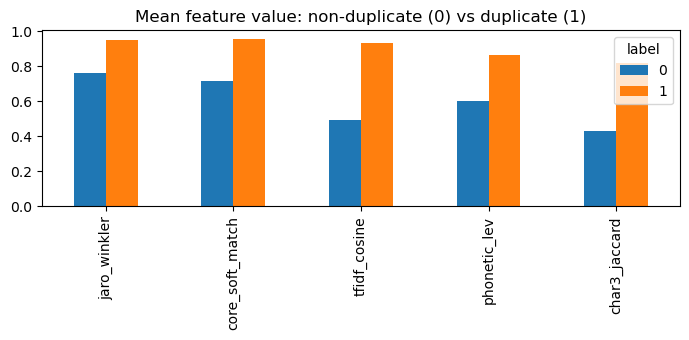

In [13]:
Xtr.assign(label=ytr).groupby("label")[["jaro_winkler","core_soft_match","tfidf_cosine","phonetic_lev","char3_jaccard"]].mean().T.plot.bar(
    figsize=(7, 3.5), title="Mean feature value: non-duplicate (0) vs duplicate (1)"); plt.tight_layout(); plt.show()

## 10. Train the three classifiers (with 5-fold grouped cross-validation)
Logistic Regression (interpretable baseline), Random Forest (non-linear), Gradient Boosting (strong tabular benchmark). CV is grouped by cooperative; the final model is later chosen on **CV F1**, never on the test set.

In [14]:
def make_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=2.0)),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=250, max_depth=3, learning_rate=0.08, random_state=SEED),
    }

fitted, cv_scores = {}, {}
for name in make_models():
    folds = []
    for a, b in GroupKFold(5).split(Xtr, ytr, gtr):
        m = make_models()[name].fit(Xtr.iloc[a], ytr[a])
        folds.append(f1_score(ytr[b], m.predict(Xtr.iloc[b])))
    cv_scores[name] = folds
    fitted[name] = make_models()[name].fit(Xtr, ytr)
    print(f"{name:20} CV F1 = {np.mean(folds):.4f} ± {np.std(folds):.4f}")

probs = {n: m.predict_proba(Xte)[:, 1] for n, m in fitted.items()}

Logistic Regression  CV F1 = 0.9504 ± 0.0034
Random Forest        CV F1 = 0.9668 ± 0.0031
Gradient Boosting    CV F1 = 0.9720 ± 0.0023


Gradient Boosting    CV F1 = 0.9714 ± 0.0047


## 11. Compare models on many metrics
All metrics on the held-out cooperatives at the default 0.5 threshold, next to the **exact-match baseline** (what a manual/normalised exact check would catch).

| Metric | What it tells you |
|---|---|
| Accuracy / Balanced accuracy | Overall correctness (balanced corrects for class imbalance) |
| Precision | Of flagged duplicates, how many are real (review-queue workload) |
| Recall | Of real duplicates, how many we catch (missed duplicates) |
| F1 | Balance of precision and recall |
| ROC-AUC | Ranking quality across all thresholds |
| PR-AUC (avg. precision) | Ranking quality focused on the duplicate class |
| MCC | Single balanced score, robust to imbalance |
| Log loss / Brier | Quality of the probabilities themselves (lower is better) |

In [15]:
def metrics_row(name, y, pred, p=None):
    r = {"model": name, "accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
         "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
         "f1": f1_score(y, pred), "mcc": matthews_corrcoef(y, pred)}
    r.update({"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
              "log_loss": log_loss(y, p), "brier": brier_score_loss(y, p)} if p is not None else
             {"roc_auc": np.nan, "pr_auc": np.nan, "log_loss": np.nan, "brier": np.nan})
    return r

rows = [metrics_row("Exact-match baseline", yte, Xte["exact_norm"].values.astype(int))]
for n in fitted:
    rows.append(metrics_row(n, yte, (probs[n] >= 0.5).astype(int), probs[n]))
results = pd.DataFrame(rows).set_index("model")
results.insert(0, "cv_f1", [np.nan] + [np.mean(cv_scores[n]) for n in fitted])
results = results.round(4)
results.to_csv(OUT / "model_metrics.csv")
display(results.style.highlight_max(axis=0, color="#cfe8cf", subset=results.columns.difference(["log_loss", "brier"]))
                     .highlight_min(axis=0, color="#cfe8cf", subset=["log_loss", "brier"]))

,cv_f1,accuracy,balanced_acc,precision,recall,f1,mcc,roc_auc,pr_auc,log_loss,brier
model,,,,,,,,,,,
Exact-match baseline,nan,0.831900,0.623700,0.980300,0.248800,0.396800,0.445700,nan,nan,nan,nan
Logistic Regression,0.950400,0.980800,0.964000,0.979000,0.933800,0.955900,0.944100,0.995100,0.984300,0.069800,0.016300
Random Forest,0.966800,0.989400,0.980700,0.987200,0.965000,0.976000,0.969300,0.998200,0.988100,0.055300,0.009100
Gradient Boosting,0.972000,0.990300,0.983500,0.984800,0.971200,0.978000,0.971800,0.998500,0.991800,0.034300,0.007900


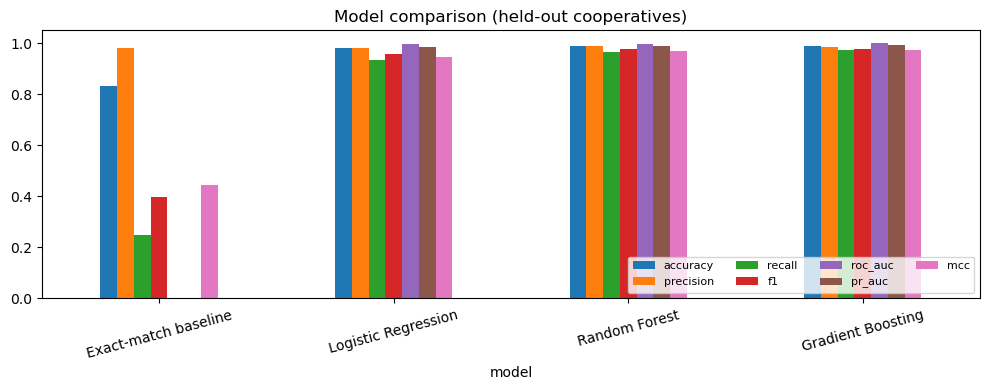

In [16]:
plot_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "mcc"]
results[plot_cols].plot.bar(figsize=(10, 4), ylim=(0, 1.05), rot=15, title="Model comparison (held-out cooperatives)")
plt.legend(ncol=4, fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Selected model (best CV F1): Gradient Boosting


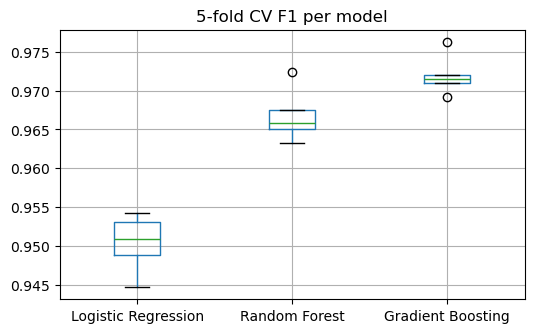

In [17]:
best = results.drop("Exact-match baseline").cv_f1.idxmax()     # chosen on CV, not on test
print("Selected model (best CV F1):", best)
pd.DataFrame(cv_scores, index=[f"fold {i+1}" for i in range(5)]).boxplot(figsize=(6, 3.5)); plt.title("5-fold CV F1 per model"); plt.show()

## 12. Confusion matrices
False negatives = missed duplicates (costly); false positives = extra work for the review officer.

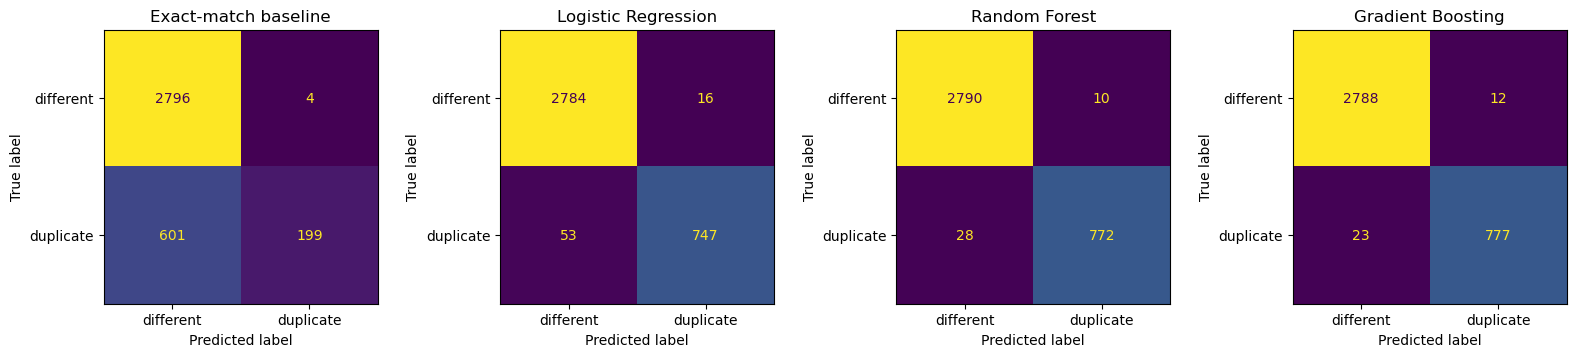

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
ConfusionMatrixDisplay(confusion_matrix(yte, Xte["exact_norm"].astype(int)), display_labels=["different", "duplicate"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Exact-match baseline")
for a, n in zip(ax[1:], fitted):
    ConfusionMatrixDisplay(confusion_matrix(yte, (probs[n] >= .5).astype(int)), display_labels=["different", "duplicate"]).plot(ax=a, colorbar=False)
    a.set_title(n)
plt.tight_layout(); plt.show()

## 13. ROC and precision-recall curves

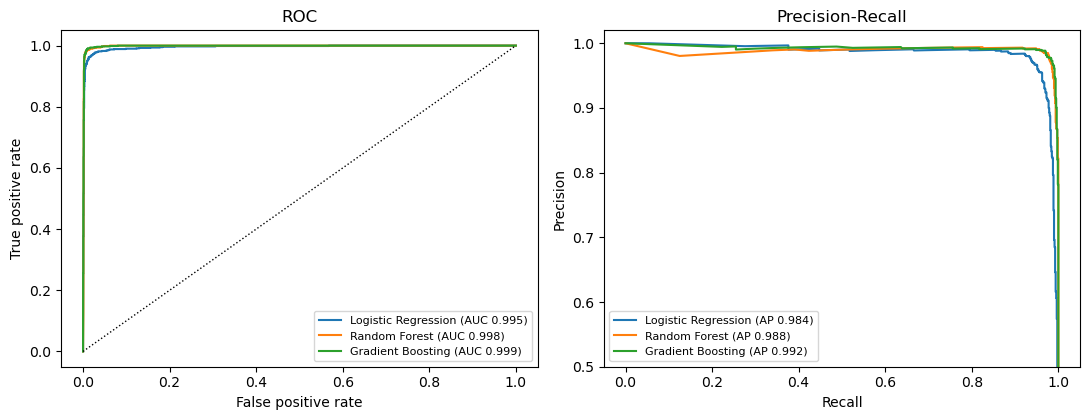

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for n, p in probs.items():
    f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=f"{n} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=f"{n} (AP {average_precision_score(yte, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall", ylim=(0.5, 1.02)); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "roc_pr_curves.png", dpi=160); plt.show()

## 14. Choosing a threshold
The 0.5 cut-off is not sacred. Sweep the threshold for the selected model to trade missed duplicates against review workload.

threshold,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
precision,0.970,0.974,0.976,0.978,0.978,0.978,0.979,0.981,0.985,0.986,0.989,0.988,0.988,0.990,0.990,0.991,0.991,0.992
recall,0.986,0.984,0.984,0.982,0.980,0.978,0.975,0.974,0.971,0.970,0.968,0.965,0.962,0.961,0.952,0.945,0.934,0.908
f1,0.978,0.979,0.980,0.980,0.979,0.978,0.977,0.977,0.978,0.978,0.978,0.977,0.975,0.975,0.971,0.967,0.961,0.948
flagged_pairs,813.000,808.000,806.000,804.000,802.000,800.000,797.000,794.000,789.000,787.000,783.000,781.000,779.000,777.000,770.000,763.000,754.000,732.000


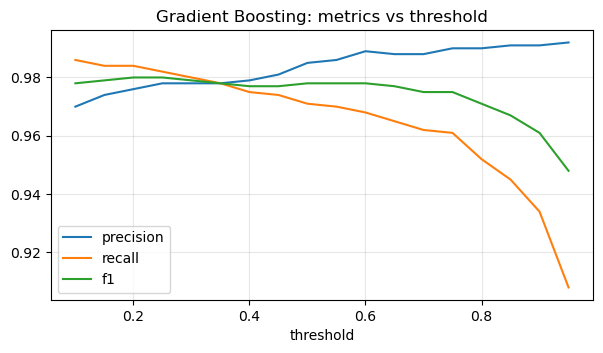

In [20]:
p = probs[best]
sweep = pd.DataFrame([{"threshold": t, "precision": precision_score(yte, p >= t, zero_division=0),
                       "recall": recall_score(yte, p >= t), "f1": f1_score(yte, p >= t),
                       "flagged_pairs": int((p >= t).sum())} for t in np.arange(0.1, 0.96, 0.05)]).round(3)
display(sweep.set_index("threshold").T)
sweep.set_index("threshold")[["precision", "recall", "f1"]].plot(figsize=(7, 3.5), title=f"{best}: metrics vs threshold"); plt.grid(alpha=.3); plt.show()

## 15. Confidence bands for the review queue
≥ 0.90 = *likely duplicate* (officer confirms), 0.50–0.90 = *review queue*, < 0.50 = *unlikely*. The true-duplicate rate in each band shows whether the bands can be trusted.

In [21]:
band = pd.cut(p, [-1, BAND_REVIEW, BAND_LIKELY, 2], labels=["unlikely", "review", "likely"])
display(pd.DataFrame({"band": band, "is_duplicate": yte}).groupby("band", observed=True).is_duplicate.agg(pairs="size", true_duplicate_rate="mean").round(3))

,pairs,true_duplicate_rate
band,,
unlikely,2811,0.008
review,35,0.857
likely,754,0.991


## 16. Which features matter?

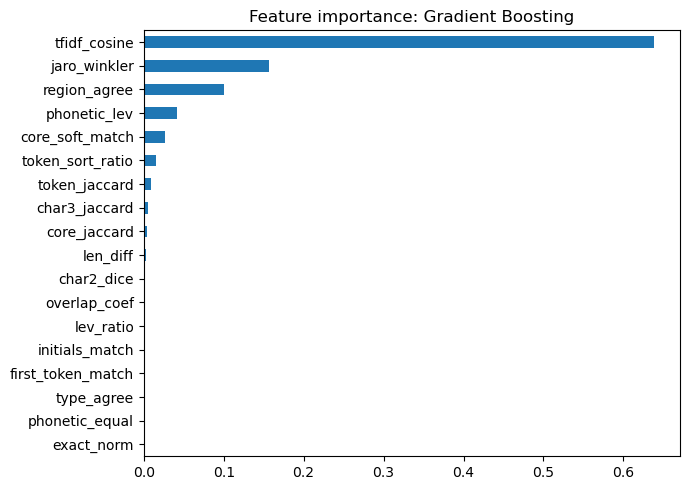

In [22]:
mdl = fitted[best]
fi = mdl.feature_importances_ if hasattr(mdl, "feature_importances_") else np.abs(mdl.named_steps["logisticregression"].coef_[0])
imp = pd.Series(fi, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7, 5), title=f"Feature importance: {best}"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4).to_csv(OUT / "feature_importance.csv", header=["importance"])

## 17. Search ranking (top-k retrieval)
A *fresh* noisy query for each held-out cooperative is searched against the whole register. Compared: normalised exact match, TF-IDF similarity alone, and each ML re-ranker. Reported as top-1/3/5 hit rate and MRR.

,top1,top3,top5,MRR
method,,,,
Logistic Regression,0.9775,0.9900,0.9900,0.9839
Random Forest,0.9875,0.9975,0.9975,0.9921
Gradient Boosting,0.9850,0.9975,0.9975,0.9912
TF-IDF only,0.9125,0.9750,0.9775,0.9445
Exact match (normalised),0.1625,0.1625,0.1625,0.1625


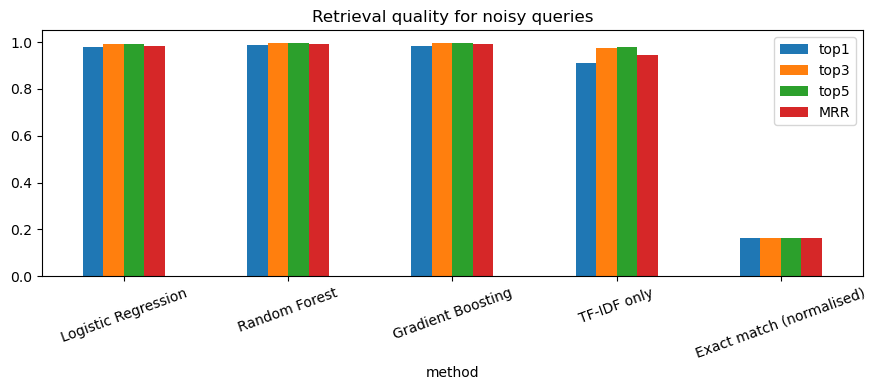

In [23]:
def retrieval_eval(register, test_ids, vec, models, rng, k=30):
    reg = register.reset_index(drop=True)
    norm = [normalize(x) for x in reg.name]
    mat = vec.transform(norm)
    pos = {c: i for i, c in enumerate(reg.coop_id)}
    queries = []
    for cid in test_ids:
        i = pos[cid]
        queries.append((i, add_noise(reg.name[i], rng, force=True), reg.region[i] if rng.random() < .85 else ""))
    rows = {m: [] for m in list(models) + ["TF-IDF only", "Exact match (normalised)"]}
    for i, q, r in queries:
        sims = (mat @ vec.transform([normalize(q)]).T).toarray().ravel()
        cand = np.argsort(-sims)[:k]
        rank_t = list(cand).index(i) + 1 if i in cand else None
        rows["TF-IDF only"].append(rank_t)
        rows["Exact match (normalised)"].append(1 if normalize(q) == norm[i] else None)
        X = pair_features([q] * len(cand), list(reg.name.iloc[cand]), [r] * len(cand),
                          list(reg.region.iloc[cand]), vec)[FEATURES]
        for m, mod in models.items():
            order = list(cand[np.argsort(-mod.predict_proba(X)[:, 1])])
            rows[m].append(order.index(i) + 1 if i in order else None)
    res = []
    for m, ranks in rows.items():
        r = np.array([x if x else np.inf for x in ranks], dtype=float)
        res.append({"method": m, "top1": np.mean(r <= 1), "top3": np.mean(r <= 3),
                    "top5": np.mean(r <= 5), "MRR": np.mean(np.where(np.isinf(r), 0, 1 / r))})
    return pd.DataFrame(res).round(4)

retrieval = retrieval_eval(register, te_e.coop_id.tolist(), vec, fitted, rng)
retrieval.to_csv(OUT / "retrieval_metrics.csv", index=False)
display(retrieval.set_index("method"))
retrieval.set_index("method")[["top1", "top3", "top5", "MRR"]].plot.bar(figsize=(9, 4), ylim=(0, 1.05), rot=20, title="Retrieval quality for noisy queries")
plt.tight_layout(); plt.show()

## 18. The search engine
Query → retrieve candidates → classify → ranked list with confidence band and plain-language evidence.

In [24]:
class NameSearch:
    def __init__(self, register, vec, model):
        self.reg, self.vec, self.model = register.reset_index(drop=True), vec, model
        self.norm = [normalize(x) for x in self.reg.name]
        self.mat = vec.transform(self.norm)

    def search(self, query, region="", top=5, k=30):
        q = vec_q = self.vec.transform([normalize(query)])
        sims = (self.mat @ vec_q.T).toarray().ravel()
        cand = np.argsort(-sims)[:k]
        X = pair_features([query] * len(cand), list(self.reg.name.iloc[cand]),
                          [region] * len(cand), list(self.reg.region.iloc[cand]), self.vec)
        p = self.model.predict_proba(X[FEATURES])[:, 1]
        out = self.reg.iloc[cand].copy()
        out["match_prob"] = p
        out["tfidf_cosine"] = sims[cand]
        out["band"] = np.where(p >= BAND_LIKELY, "LIKELY DUPLICATE - officer to confirm",
                      np.where(p >= BAND_REVIEW, "REVIEW QUEUE", "unlikely"))
        out["evidence"] = [evidence(r) for _, r in X.iterrows()]
        return out.sort_values("match_prob", ascending=False).head(top).reset_index(drop=True)

engine = NameSearch(register, vec, fitted[best])
target = register.iloc[10]
query = add_noise(target["name"], rng, force=True)
print(f"True name: {target['name']} ({target['region']})\nQuery    : {query}\n")
display(engine.search(query, target["region"], top=5)[["coop_id", "name", "region", "match_prob", "band", "evidence"]].round(3))

True name: Upendo SACCOS Ltd (Arusha)
Query    : UPENDO SACCOS ltd



,coop_id,name,region,match_prob,band,evidence
0,C00010,Upendo SACCOS Ltd,Arusha,1.000,LIKELY DUPLICATE - officer to confirm,identical after normalisation; distinctive words agree (100%); character n-g...
1,C00196,Upendo Kijiji SACCOS Ltd,Dar es Salaam,0.002,unlikely,different region
2,C00970,Upendo Vijana SACCOS Ltd,Mbeya,0.002,unlikely,different region
3,C01411,Upendo Msingi SACCOS Ltd,Rukwa,0.001,unlikely,different region
4,C00268,Upendo Msingi Coffee AMCOS Ltd,Geita,0.001,unlikely,different region; different society type


In [25]:
# Screening a *proposed* new name (no region given)
for proposed in ["Umoja Dairy Cooperative Society", "Zzyx Qwerty Dairy Cooperative Society"]:
    print("Proposed:", proposed)
    display(engine.search(proposed, "", top=3)[["name", "region", "match_prob", "band", "evidence"]].round(3))

Proposed: Umoja Dairy Cooperative Society


,name,region,match_prob,band,evidence
0,Jua Umoja Dairy Cooperative Society Ltd,Tabora,0.038,unlikely,character n-grams overlap (79%)
1,Wavuvi Umoja Dairy Cooperative Society Ltd,Njombe,0.025,unlikely,character n-grams overlap (74%)
2,Pamoja Dairy Cooperative Society Ltd,Kagera,0.022,unlikely,character n-grams overlap (76%)


Proposed: Zzyx Qwerty Dairy Cooperative Society


,name,region,match_prob,band,evidence
0,Amani Dairy Cooperative Society Ltd,Rukwa,0.018,unlikely,distinctive words differ
1,Jua Dairy Cooperative Society Ltd,Lindi,0.011,unlikely,distinctive words differ
2,Mwanga Dairy Cooperative Society Ltd,Ruvuma,0.008,unlikely,distinctive words differ


## 19. Review queue and saving
Possible duplicates already inside the register, ready for an officer to mark *same / different / needs more info*. Nothing is merged automatically.

In [26]:
queue = []
for _, r in register.sample(300, random_state=SEED).iterrows():
    h = engine.search(r["name"], r["region"], top=2)
    h = h[h.coop_id != r.coop_id].head(1)
    if len(h) and h.match_prob.iloc[0] >= BAND_REVIEW:
        queue.append({"coop_id": r.coop_id, "name": r["name"], "candidate_id": h.coop_id.iloc[0], "candidate_name": h.name.iloc[0],
                      "match_prob": round(h.match_prob.iloc[0], 3), "band": h.band.iloc[0], "evidence": h.evidence.iloc[0], "officer_decision": ""})
queue = pd.DataFrame(queue); queue.to_csv(OUT / "review_queue_sample.csv", index=False)
print(len(queue), "pairs queued for review"); display(queue.head())
joblib.dump({"register": register, "vec": vec, "model": fitted[best], "model_name": best}, OUT / "name_search_model.joblib")
print("Saved to", OUT.resolve())

22 pairs queued for review


,coop_id,name,candidate_id,candidate_name,match_prob,band,evidence,officer_decision
0,C00056,Ushindi Harambee SACCOS Ltd,C00037,Ushindi SACCOS Ltd,0.829,REVIEW QUEUE,same region,
1,C00029,Mlima Mto SACCOS Ltd,C00038,Mlima SACCOS Ltd,0.589,REVIEW QUEUE,character n-grams overlap (71%); same region,
2,C00069,Tumaini SACCOS Ltd,C00185,Juhudi Tumaini SACCOS Ltd,0.560,REVIEW QUEUE,character n-grams overlap (72%); same region,
3,C00583,Chemchem Baraka Livestock Cooperative Society Ltd,C00609,Chemchem Faraja Livestock Cooperative Society Ltd,0.988,LIKELY DUPLICATE - officer to confirm,distinctive words agree (93%); character n-grams overlap (77%); same region,
4,C01785,Mkombozi Nuru Fishing Cooperative Society Ltd,C01895,Mkombozi Umoja Fishing Cooperative Society Ltd,0.516,REVIEW QUEUE,character n-grams overlap (75%); same region,


Saved to C:\Users\GEN-X\Downloads\coop_search_outputs


## 20. Reading the results (and limits)
* Every ML model beats the exact-match baseline on **recall and F1** by a wide margin; exact match is precise but misses most variants.
* Compare **PR-AUC, MCC and log loss** as well as F1: they separate models that look identical on accuracy.
* Use the threshold sweep (Step 14) to pick the review-queue operating point with the officers.
* **Limits:** names and duplicates here are simulated, and real registers have far fewer duplicates than the 22% simulated here (so expect lower precision at the same threshold). Validate on officer-labelled real pairs before reporting accuracy in the capstone.